# House Price Prediction using linear regression, single input variable

In [1]:
# importing the libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# installing the libraries:

%pip install --upgrade --force-reinstall scikit-learn scipy

  Using cached numpy-2.4.6-cp311-cp311-macosx_14_0_arm64.whl.metadata (6.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 23.1 MB/s  0:00:002.7 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.3/20.3 MB 3.4 MB/s  0:00:05a 0:00:01m eta 0:00:01
Using cached numpy-2.4.6-cp311-cp311-macosx_14_0_arm64.whl (5.5 MB)
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.6.0
    Uninstalling threadpoolctl-3.6.0:
      Successfully uninstalled threadpoolctl-3.6.0━━━━ 0/7 [threadpoolctl]
  Attempting uninstall: numpy━━━━━━━━━━━━━━━━━━━━━ 0/7 [threadpoolctl]
    Found existing installation: numpy 2.4.4━━━━━━ 0/7 [threadpoolctl]
    Uninstalling numpy-2.4.4:━━━━━━━━━━━━━━━━━━━━━ 0/7 [threadpoolctl]
      Successfully uninstalled numpy-2.4.4━━━━━━━━ 0/7 [threadpoolctl]
  Attempting uninstall: narwhals38;2;249;38;114m╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1/7 [numpy]
    Found existing installation: narwhals 1.48.1m━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [4]:
# dataset from kaggle Housing.csv

df = pd.read_csv("Housing.csv")

In [5]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [6]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [24]:
df.columns

Index(['area', 'price'], dtype='object')

In [8]:
df.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [9]:
# since we are doing a linear regression, single input variable we are gonna just take 2 features.
df = df[["area", "price"]]

In [10]:
df.head()

,area,price
0,7420,13300000
1,8960,12250000
2,9960,12250000
3,7500,12215000
4,7420,11410000


In [11]:
df.count()

area     545
price    545
dtype: int64

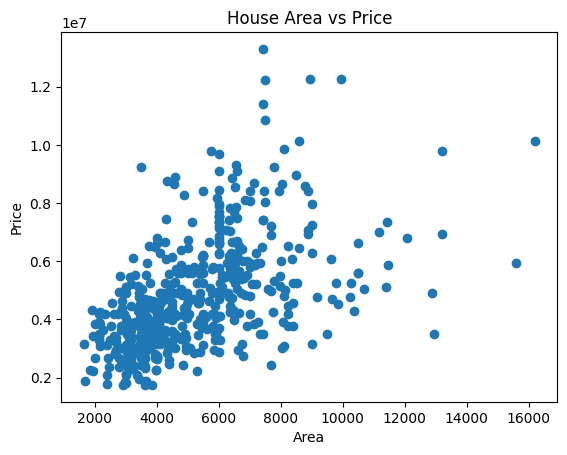

In [12]:
# data seeing visually.

plt.scatter(df["area"], df["price"])

plt.xlabel("Area")
plt.ylabel("Price")
plt.title("House Area vs Price")
plt.show()

In [14]:
# seperating X and y

X = df[["area"]] # this is input(X) - y
y = df["price"] # this is output(Y) - y_hat

print(X.shape) # area
print(y.shape) # price to predict

(545, 1)
(545,)


In [16]:
# now Split into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [17]:
print(len(X_train))
print(len(X_test))

436
109


In [18]:
# model training

model = LinearRegression()
model.fit(X_train, y_train) # .fit() learns the weight and bias by minimizing prediction errors

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 425.72984193878284
Intercept: 2512254.2639593435


In [20]:
# prediction, Compare the predicted prices with the actual prices.

y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])
print("\nFirst 10 actual prices:")
print(y_test.head(10).to_numpy())

First 10 predictions:
[5024060.33139816 5279498.23656143 4232202.82539203 4640903.47365326
 4198144.43803692 5373158.80178796 6139472.51727777 4636646.17523387
 3891618.951841   3661724.83719406]

First 10 actual prices:
[4060000 6650000 3710000 6440000 2800000 4900000 5250000 4543000 2450000
 3353000]


In [21]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R²:", r2)

MAE: 1474748.1337969352
RMSE: 1917103.7021424233
R²: 0.27287851871974644


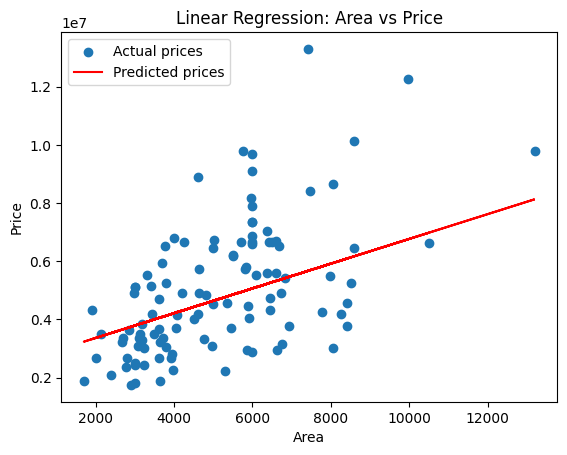

In [22]:
plt.scatter(X_test["area"], y_test, label="Actual prices")

plt.plot(
    X_test["area"],
    y_pred,
    color="red",
    label="Predicted prices"
)

plt.xlabel("Area")
plt.ylabel("Price")
plt.title("Linear Regression: Area vs Price")
plt.legend()
plt.show()